# Week 2: Monthly Cohort Retention Analysis

**Source:** `cleaned_transactions` in local PostgreSQL (`retail_analytics`)  
**Goal:** Measure Month+0 through Month+12 customer retention and persist `cohort_retention` for Power BI.

## 1. Portable PostgreSQL Connection & Transaction Load

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('PG_USER')}:{os.getenv('PG_PASSWORD')}"
    f"@{os.getenv('PG_HOST')}:{os.getenv('PG_PORT')}/{os.getenv('PG_DB')}"
)

tx = pd.read_sql(
    "SELECT customer_id, invoice, invoice_date, line_revenue FROM cleaned_transactions",
    engine,
)
tx["invoice_date"] = pd.to_datetime(tx["invoice_date"])
print(f"Loaded {len(tx):,} transaction lines for {tx['customer_id'].nunique():,} customers")
tx.head()

Loaded 399,568 transaction lines for 4,285 customers


,customer_id,invoice,invoice_date,line_revenue
0,13085,489434,2009-12-01 07:45:00,83.4
1,13085,489434,2009-12-01 07:45:00,81.0
2,13085,489434,2009-12-01 07:45:00,81.0
3,13085,489434,2009-12-01 07:45:00,100.8
4,13085,489434,2009-12-01 07:45:00,30.0


## 2. Assign Acquisition Cohorts & Cohort Index

In [2]:
tx["invoice_month"] = tx["invoice_date"].dt.to_period("M")
tx["cohort_month"] = tx.groupby("customer_id")["invoice_month"].transform("min")

tx["cohort_index"] = (
    (tx["invoice_month"].dt.year - tx["cohort_month"].dt.year) * 12
    + (tx["invoice_month"].dt.month - tx["cohort_month"].dt.month)
)

cohort_counts = (
    tx.groupby(["cohort_month", "cohort_index"])["customer_id"]
    .nunique()
    .reset_index(name="active_customers")
)

cohort_pivot = cohort_counts.pivot(
    index="cohort_month", columns="cohort_index", values="active_customers"
)
cohort_sizes = cohort_pivot[0]
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0) * 100

display(retention_matrix.round(1))

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2009-12,100.0,35.0,33.3,42.5,37.9,36.0,37.6,34.4,33.8,36.2,42.2,49.6,24.8
2010-01,100.0,21.5,32.1,31.5,27.2,31.0,26.9,23.4,28.5,32.6,31.0,10.3,NaN
2010-02,100.0,23.5,22.7,29.3,24.5,19.7,19.2,28.8,25.6,27.7,7.2,NaN,NaN
2010-03,100.0,19.0,23.1,24.3,23.1,20.4,24.7,30.6,27.7,7.9,NaN,NaN,NaN
2010-04,100.0,19.0,19.0,16.0,18.4,22.1,27.6,26.5,6.8,NaN,NaN,NaN,NaN
2010-05,100.0,15.7,16.9,17.6,17.6,25.5,21.2,7.8,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.6,18.7,20.6,23.2,28.5,6.7,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.7,18.4,29.7,29.2,10.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,19.6,28.8,32.5,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Cohort Retention Heatmap

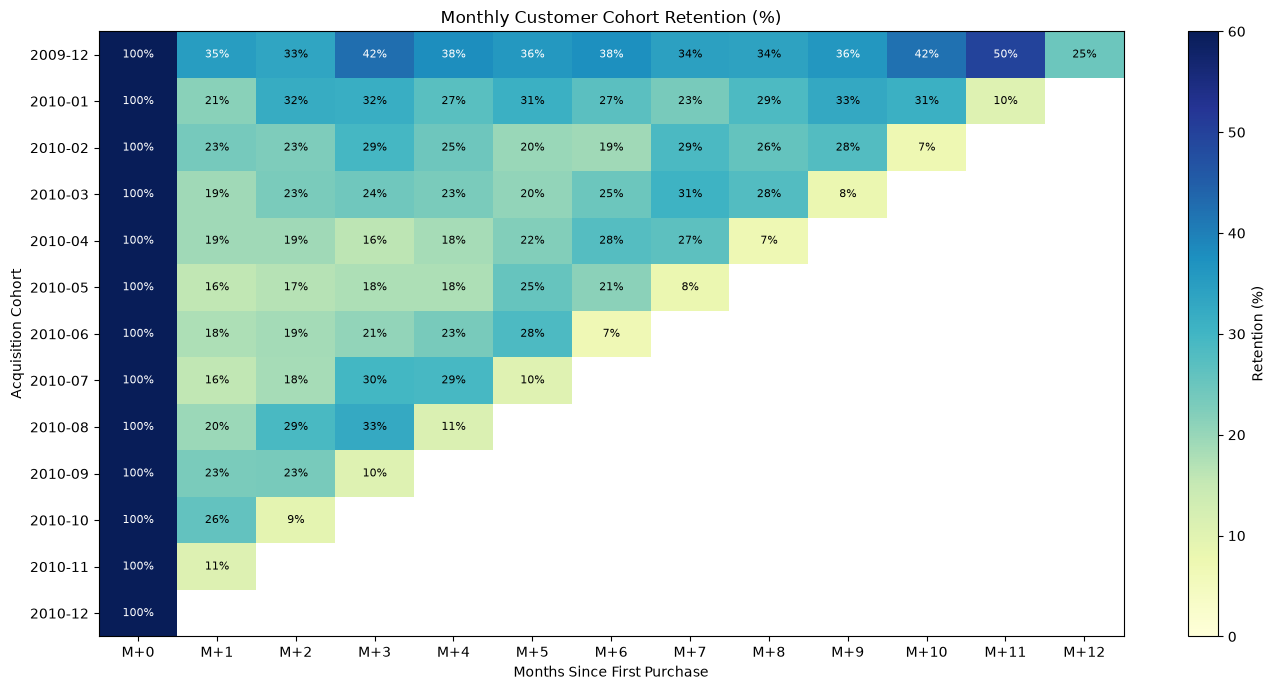

In [3]:
fig, ax = plt.subplots(figsize=(14, 7))
data = retention_matrix.to_numpy()
im = ax.imshow(data, cmap="YlGnBu", aspect="auto", vmin=0, vmax=60)

ax.set_xticks(np.arange(retention_matrix.shape[1]))
ax.set_xticklabels([f"M+{c}" for c in retention_matrix.columns])
ax.set_yticks(np.arange(retention_matrix.shape[0]))
ax.set_yticklabels([str(idx) for idx in retention_matrix.index])
ax.set_title("Monthly Customer Cohort Retention (%)")
ax.set_xlabel("Months Since First Purchase")
ax.set_ylabel("Acquisition Cohort")

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if not np.isnan(val):
            color = "white" if val > 35 else "black"
            ax.text(j, i, f"{val:.0f}%", ha="center", va="center", color=color, fontsize=8)

fig.colorbar(im, ax=ax, label="Retention (%)")
plt.tight_layout()
plt.show()

## 4. Average Retention Curve (Month+1 to Month+12)

,cohort_index,avg_retention_pct
0,1,20.52
1,2,22.35
2,3,25.45
3,4,23.57
4,5,24.18
5,6,23.42
6,7,25.26
7,8,24.47
8,9,26.11
9,10,26.78


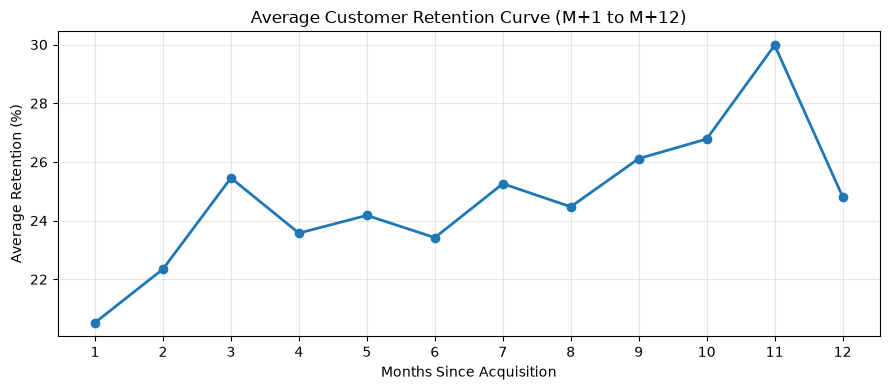

In [4]:
avg_retention = (
    retention_matrix.drop(columns=[0])
    .mean(axis=0)
    .reset_index()
)
avg_retention.columns = ["cohort_index", "avg_retention_pct"]
display(avg_retention.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(avg_retention["cohort_index"], avg_retention["avg_retention_pct"], marker="o", linewidth=2)
ax.set_title("Average Customer Retention Curve (M+1 to M+12)")
ax.set_xlabel("Months Since Acquisition")
ax.set_ylabel("Average Retention (%)")
ax.set_xticks(avg_retention["cohort_index"])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Persist `cohort_retention` to PostgreSQL & CSV

In [5]:
cohort_export = cohort_counts.merge(
    cohort_sizes.rename("cohort_size").reset_index(),
    on="cohort_month",
    how="left",
)
cohort_export["retention_pct"] = (
    cohort_export["active_customers"] / cohort_export["cohort_size"] * 100
).round(2)
cohort_export["cohort_month"] = cohort_export["cohort_month"].astype(str)

out_dir = PROJECT_ROOT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)

cohort_export.to_csv(out_dir / "cohort_retention_week2.csv", index=False)
cohort_export.to_sql("cohort_retention", engine, if_exists="replace", index=False)
print(f"Saved {len(cohort_export):,} cohort rows to PostgreSQL and data/processed/cohort_retention_week2.csv")

Saved 91 cohort rows to PostgreSQL and data/processed/cohort_retention_week2.csv
